## Versioned research workflow
Run from the project root. The frozen March–July benchmark is available below for historical inspection.

In [ ]:
from scripts.wp03_compare import run
from threadpoolctl import threadpool_limits

# Select expanded only after all source partitions have been reconciled.
experiment = "local_through_september"
with threadpool_limits(limits=1):
    display(run(experiment))

# WP02 retrospective spike validation
Run from the project root. Run eda.ipynb before model.ipynb. WP02 outputs are written to wp02/. The original WP01 cells and their stored outputs follow for comparison.

In [ ]:
# Frozen benchmark: see docs/REPRODUCE.md for an isolated rerun.
if False:
    from wp02_model import evaluate
    evaluate()

## Historical analysis
Historical cells are skipped during Run All. Enabling them can fetch data and overwrite historical exports.

In [ ]:
from IPython.core.magic import register_cell_magic

RUN_HISTORICAL = False

@register_cell_magic
def historical(line, cell):
    if RUN_HISTORICAL:
        get_ipython().run_cell(cell).raise_error()

## Given a spike candidate, can the model classify it as a real pollution event or a fake sensor artifact?

1. Choose modelling features and remove leakage columns.
2. Split data by time, not randomly.
3. Train a simple baseline model.



- suspected_fake_sensor_artifact:            299
- confirmed_real_close_duration:              431

*for secondary experiment:*
- spatially_supported_different_duration:      18

*for semi-supervised:*
- unconfirmed_no_neighbours:                 476
- isolated_unconfirmed:                      816

Excluding the direct rule columns and use more general features, such as:

pm2p5,
rolling_mean,
rolling_std,
z_score,
pm2p5_diff,
target_duration_timesteps,
event_max_pm2p5,
event_mean_pm2p5,
drop_after_event,
hour_of_day,
day_of_week,
sensor reliability features,
recent missingness,
baseline variability

For a defensible first model, avoid these as input features:

rule_label,
ml_label,
suspected_fake,
sharp_jump,
sharp_drop_after_event,
returns_to_normal_quickly,
n_close_duration_neighbours,
close_duration_neighbour_ids,
duration_close_match

These define what is fake and what's real, so we avoid this so that our model doesn't just learn our rules but is able to seperate real from fake by itself. These columns either directly created the label or strongly reveal the rule used to create the label.

In [1]:
%%historical
import pandas as pd
import numpy as np
from pathlib import Path

labelled_spike_candidates = pd.read_csv("labelled_spike_candidates.csv")

# Make sure timestamps are datetime again
labelled_spike_candidates["timestamp"] = pd.to_datetime(
    labelled_spike_candidates["timestamp"]
)

print(labelled_spike_candidates.shape)
print(labelled_spike_candidates["rule_label"].value_counts())

(2040, 46)
rule_label
isolated_unconfirmed                      816
unconfirmed_no_neighbours                 476
confirmed_real_close_duration             431
suspected_fake_sensor_artifact            299
spatially_supported_different_duration     18
Name: count, dtype: int64


In [2]:
%%historical
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Start from labelled spike candidates
# --------------------------------------------------

model_df = labelled_spike_candidates.copy()

# Choose the label column
label_col = "rule_label"   # change this if your label column has a different name

real_labels = [
    "confirmed_real_close_duration"
   # keep "spatially_supported_different_duration" out of the real labels for now, since it is a bit ambiguous and we don't have many examples of it
]

fake_labels = [
    "suspected_fake_sensor_artifact"
]

# Keep only rows that have usable real/fake labels
model_df = model_df[
    model_df[label_col].isin(real_labels + fake_labels)
].copy()

# Encode target
# real = 1, fake = 0
model_df["target"] = np.where(
    model_df[label_col].isin(real_labels),
    1,
    0
)

model_df["target_name"] = model_df["target"].map({
    1: "real",
    0: "fake"
})

print("Label counts:")
print(model_df["target_name"].value_counts())

Label counts:
target_name
real    431
fake    299
Name: count, dtype: int64


In [3]:
%%historical
# --------------------------------------------------
# Feature engineering
# --------------------------------------------------

model_df["timestamp"] = pd.to_datetime(model_df["timestamp"])

# Time features
model_df["hour"] = model_df["timestamp"].dt.hour
model_df["day_of_week"] = model_df["timestamp"].dt.dayofweek
model_df["month"] = model_df["timestamp"].dt.month
model_df["is_weekend"] = model_df["day_of_week"].isin([5, 6]).astype(int)

# Spike intensity relative to local baseline
model_df["pm2p5_above_baseline"] = (
    model_df["pm2p5"] - model_df["rolling_mean"]
)

model_df["pm2p5_ratio_to_baseline"] = (
    model_df["pm2p5"] / (model_df["rolling_mean"] + 1e-6)
)

model_df["event_peak_above_baseline"] = (
    model_df["event_max_pm2p5"] - model_df["rolling_mean"]
)

model_df["event_mean_above_baseline"] = (
    model_df["event_mean_pm2p5"] - model_df["rolling_mean"]
)

# rename for clarity
model_df = model_df.rename(columns={
    "n_neighbours_checked": "n_available_neighbours_checked"
})

candidate_features = [
    # Spike magnitude / local baseline
    "pm2p5",
    "rolling_mean",
    "rolling_std",
    "z_score",
    "pm2p5_diff",

    # Event-level shape
    "target_duration_timesteps",
    "event_max_pm2p5",
    "event_mean_pm2p5",

    # Engineered intensity features
    "pm2p5_above_baseline",
    "pm2p5_ratio_to_baseline",
    "event_peak_above_baseline",
    "event_mean_above_baseline",

    # Time context
    "hour",
    "day_of_week",
    "month",
    "is_weekend",

    # spatial context
    "n_available_neighbours_checked",

    # Other sensor measurements if available
    "temperature",
    "humidity",
    "pm1p0",
    "pm10p0",
    "pm4p0",
    "voc",
    "nox",
    "co2"
]

# Keep only features that actually exist in your dataframe
feature_cols = [col for col in candidate_features if col in model_df.columns]

print("Features used:")
print(feature_cols)

print("\nNumber of features:", len(feature_cols))

Features used:
['pm2p5', 'rolling_mean', 'rolling_std', 'z_score', 'pm2p5_diff', 'target_duration_timesteps', 'event_max_pm2p5', 'event_mean_pm2p5', 'pm2p5_above_baseline', 'pm2p5_ratio_to_baseline', 'event_peak_above_baseline', 'event_mean_above_baseline', 'hour', 'day_of_week', 'month', 'is_weekend', 'n_available_neighbours_checked', 'temperature', 'humidity', 'pm1p0', 'pm10p0', 'pm4p0', 'voc', 'nox', 'co2']

Number of features: 25


## EXPLORATORY DATA ANALYSIS ON LABELLED DATASET

**TIME COVERAGE**

- earliest and latest spike timestamps,
- number of labelled spikes per day, week, or month,
- real and fake spike counts over time,
- whether some periods contain mostly one class,
- whether there are long periods with no labelled events.

This shows whether the training period is representative of the future test period.

For example:

If real spikes occur mainly in March and fake spikes mainly in June, the model may confuse time-related changes with spike type.
If sensor behaviour changes over time, test performance may decrease even when the feature patterns initially appear clear.
If the test period contains stations or pollution conditions not present in training, it becomes a more difficult but more realistic evaluation.

In [4]:
%%historical
# earliest and latest timestamps in the dataset
earliest_timestamp = model_df["timestamp"].min()
latest_timestamp = model_df["timestamp"].max()

print(f"Earliest timestamp: {earliest_timestamp}")
print(f"Latest timestamp: {latest_timestamp}")

Earliest timestamp: 2026-03-04 22:00:00
Latest timestamp: 2026-07-31 20:00:00


C:\Users\okwuk\AppData\Local\Temp\ipykernel_2996\553317327.py:9: FutureWarning: DataFrameGroupBy.resample operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .size()


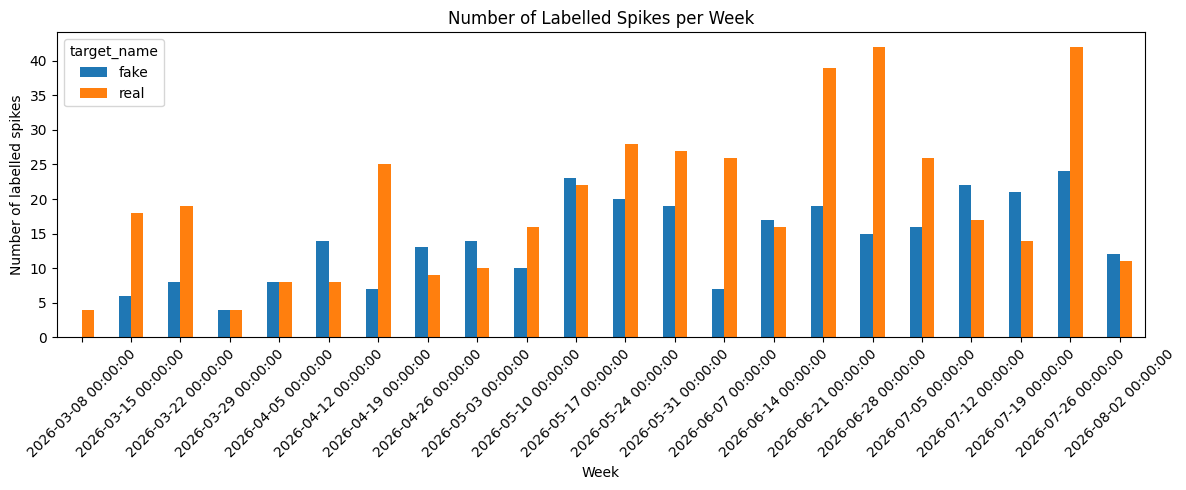

In [5]:
%%historical
import matplotlib.pyplot as plt

# Count the number of labelled spike events per week
spikes_per_week = (
    model_df
    .set_index("timestamp")
    .groupby("target_name")
    .resample("W")
    .size()
    .unstack(level=0, fill_value=0)
)

# Plot the weekly counts
spikes_per_week.plot(
    kind="bar",
    figsize=(12, 5),
    title="Number of Labelled Spikes per Week"
)

plt.xlabel("Week")
plt.ylabel("Number of labelled spikes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The weekly distribution of labelled spikes changes considerably over time. Earlier periods contain fewer observations and are generally dominated by fake spikes, while real spikes become more frequent during the later weeks, particularly in June. This indicates temporal variation and a class-distribution shift between the training and future test periods. The result supports using a time-based split because it provides a realistic assessment of whether the model can generalise to future periods where the prevalence of real and fake spikes may differ. However, the source of the weekly variation should also be investigated, as it may result from environmental changes, sensor availability, data completeness or changes in labelling coverage.

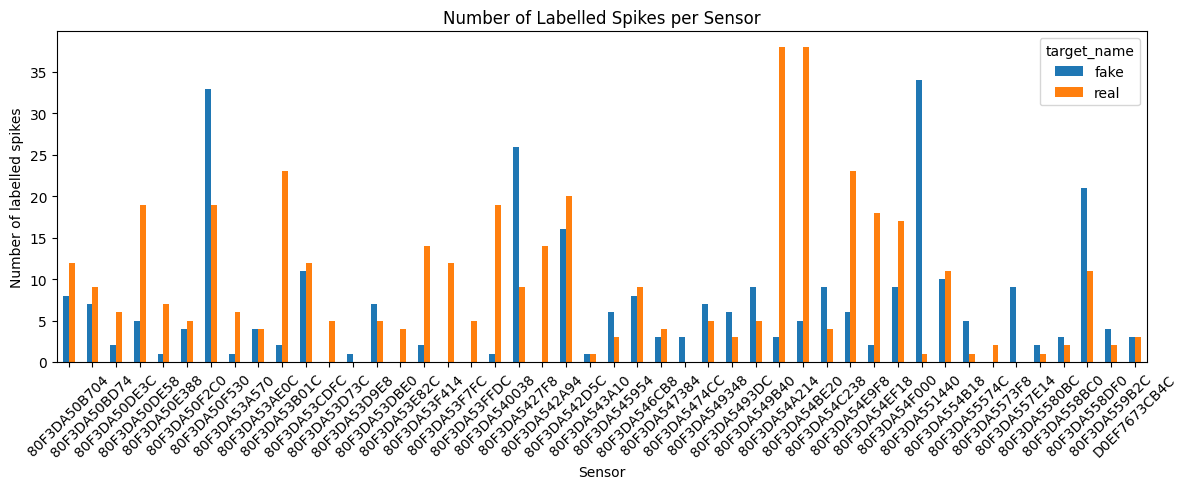

In [6]:
%%historical
spikes_per_sensor = (
    model_df
    .groupby("sensor_id")["target_name"]
    .value_counts()
    .unstack(level=1, fill_value=0)
)

spikes_per_sensor.plot(
    kind="bar",
    figsize=(12, 5),
    title="Number of Labelled Spikes per Sensor"
)
plt.xlabel("Sensor")
plt.ylabel("Number of labelled spikes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The distribution of labelled spikes varies considerably between sensors. A small number of sensors contribute a disproportionately large number of fake spikes, while real spikes are more widely distributed across the sensor network. This suggests that fake spikes may partly reflect sensor-specific behaviour or sensor-quality problems. Consequently, the classification model may become influenced by the dominant sensors rather than learning fully general characteristics of real and fake spikes. The current time-based split remains appropriate for evaluating future performance on the existing sensor network, but an additional sensor-grouped validation should later be used to assess whether the model generalises to unseen sensors. Sensors with unusually high fake-spike counts should also be examined for reliability, missing data and possible hardware or calibration issues.

**Features used: ['pm2p5', 'rolling_mean', 'rolling_std', 'z_score', 'pm2p5_diff', 'target_duration_timesteps', 'event_max_pm2p5', 'event_mean_pm2p5', 'pm2p5_above_baseline', 'pm2p5_ratio_to_baseline', 'event_peak_above_baseline', 'event_mean_above_baseline', 'hour', 'day_of_week', 'month', 'is_weekend', 'n_available_neighbours_checked', 'temperature', 'humidity', 'pm1p0', 'pm10p0', 'pm4p0', 'voc', 'nox', 'co2']**

Number of features: 25

Did not include: sharp_jump, sharp_drop_after_event, returns_to_normal_quickly, n_active_neighbour_spikes, max_neighbour_duration, mean_neighbour_duration because they are directly related to the model

Examine individual feature distributions

For every numerical feature, we should compare:

- overall distribution,
- real spike distribution,
- fake spike distribution,
- median,
- mean,
- spread,
- minimum and maximum,
- extreme values.

The main features should be grouped logically.

**Spike magnitude and baseline-deviation features: These tell us whether real spikes tend to be larger or smaller than fake spikes.**

pm2p5
rolling_mean
rolling_std
z_score
pm2p5_diff
event_max_pm2p5
event_mean_pm2p5
pm2p5_above_baseline
pm2p5_ratio_to_baseline
event_peak_above_baseline
event_mean_above_baseline

**Spike shape features: These tell us whether fake spikes tend to be short, sharp and isolated.**

target_duration_timesteps

**Temporal features: They can help reveal whether real or fake spikes tend to happen at particular times of day, on particular days, during certain months, on weekdays versus weekends.**

hour
day_of_week
month
is_weekend

**Spatial support features: These tell us whether real spikes are spatially supported.**

n_available_neighbours_checked


**Environmental features: These may help us determine whether a spike is part of a wider pollution event or is inconsistent with the other sensor channels.**

temperature,
humidity,
PM1.0,
PM4.0,
PM10.0,
VOC,
NOx,
CO₂.


We will verify how strongly the labelled dataset reflects the assumptions used to create the labels.

In [7]:
%%historical
# display all features in the dataset
labelled_spike_candidates.columns

Index(['sensor_id', 'station', 'timestamp', 'pm2p5', 'actual_readings',
       'expected_readings', 'reliable', 'pm2p5_for_stats', 'rolling_mean',
       'rolling_std', 'rolling_std_safe', 'z_score', 'pm2p5_diff',
       'previous_reliable', 'spike_event_id', 'event_start_time',
       'event_end_time', 'target_duration_timesteps', 'event_max_pm2p5',
       'event_mean_pm2p5', 'candidate_id', 'n_neighbours_checked',
       'n_active_neighbour_spikes', 'max_neighbour_duration',
       'mean_neighbour_duration', 'n_close_duration_neighbours',
       'close_duration_neighbour_ids', 'next_pm2p5', 'next_z_score',
       'next_rolling_mean', 'next_rolling_std', 'next_is_spike', 'sharp_jump',
       'drop_after_event', 'sharp_drop_after_event',
       'returns_to_normal_quickly', 'suspected_fake', 'rule_label',
       'temperature', 'humidity', 'pm1p0', 'pm10p0', 'pm4p0', 'voc', 'nox',
       'co2'],
      dtype='object')

In [8]:
%%historical
# how many sensors are in the dataset
model_df["sensor_id"].nunique()

46

In [9]:
%%historical
# Prepare X and y for ML model training

X = model_df[feature_cols].copy()
y = model_df["target"].copy()

# missing value check
print("\nMissing values per features:")
print(X.isna().sum().sort_values(ascending=False))


Missing values per features:
pm2p5                             0
rolling_mean                      0
rolling_std                       0
z_score                           0
pm2p5_diff                        0
target_duration_timesteps         0
event_max_pm2p5                   0
event_mean_pm2p5                  0
pm2p5_above_baseline              0
pm2p5_ratio_to_baseline           0
event_peak_above_baseline         0
event_mean_above_baseline         0
hour                              0
day_of_week                       0
month                             0
is_weekend                        0
n_available_neighbours_checked    0
temperature                       0
humidity                          0
pm1p0                             0
pm10p0                            0
pm4p0                             0
voc                               0
nox                               0
co2                               0
dtype: int64


### USING A TIME-BASED SPLIT INSTEAD OF RANDOM
We use a time-based split because this is time-series sensor data. The model should learn from older spike events and be tested on newer spike events. A random split can leak future information into training and make performance look unrealistically good.

In [ ]:
%%historical
# --------------------------------------------------
# Chronological train/test split
# Keep all observations at the same timestamp together
# --------------------------------------------------

model_df = model_df.sort_values("timestamp").reset_index(drop=True)

split_frac = 0.75
split_idx = int(len(model_df) * split_frac)

# Use the first test timestamp as the boundary
split_time = model_df.iloc[split_idx]["timestamp"]

# Strictly separate timestamps across the boundary
train_df = model_df[model_df["timestamp"] < split_time].copy()
test_df = model_df[model_df["timestamp"] >= split_time].copy()

# Check whether the same sensor event spans both splits
event_keys = ["sensor_id", "spike_event_id"]

train_events = set(
    map(tuple, train_df[event_keys].to_numpy())
)

test_events = set(
    map(tuple, test_df[event_keys].to_numpy())
)

shared_events = train_events.intersection(test_events)

print("Split boundary:", split_time)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Events crossing boundary:", len(shared_events))
print("Shared sensor-event IDs:", sorted(shared_events))

# Prepare modelling arrays
X_train = train_df[feature_cols].copy()
y_train = train_df["target"].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df["target"].copy()

Training period:
2026-03-04 22:00:00 to 2026-07-03 20:00:00

Testing period:
2026-07-03 20:00:00 to 2026-07-31 20:00:00

Training label counts:
target_name
real    332
fake    215
Name: count, dtype: int64

Testing label counts:
target_name
real    99
fake    84
Name: count, dtype: int64


1. Keep your chronological train/test split.
2. Use stratified k-fold only on the training set.
3. Compare feature sets or Logistic Regression settings.
4. Pick the best setup based on cross-validation.
5. Train that final setup on the full training set.
6. Evaluate once on the untouched future test set.

In [11]:
%%historical
# Logistic Regression Model
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistic_model = make_pipeline(
    SimpleImputer(strategy='median'), # median imputation is safer because missing values get replaced with a more typical value
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
)

logistic_model.fit(X_train, y_train)

print("model trained successfully")

model trained successfully


In [12]:
%%historical
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

y_pred = logistic_model.predict(X_test)
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1] # probability of the positive class (real)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["fake", "real"]))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ROC-AUC only works if both classes are present in test set
if y_test.nunique() == 2:
    print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Average precision:", average_precision_score(y_test, y_pred_proba))
else:
    print("ROC-AUC not calculated because the test set has only one class.")

Classification Report:
              precision    recall  f1-score   support

        fake       0.61      0.88      0.72        84
        real       0.84      0.53      0.65        99

    accuracy                           0.69       183
   macro avg       0.73      0.70      0.68       183
weighted avg       0.73      0.69      0.68       183

Confusion Matrix:
[[74 10]
 [47 52]]
ROC-AUC: 0.8002645502645502
Average precision: 0.8502412398740751


In [13]:
%%historical
# hyperparameter tuning with GridSearchCV
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import numpy as np

tuned_pipeline = make_pipeline( 
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(class_weight='balanced', penalty='l2', solver='lbfgs', max_iter=5000, random_state=42)
)

param_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

tscv = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(estimator=tuned_pipeline, param_grid=param_grid, cv=tscv, scoring='average_precision', n_jobs=1)

grid_search.fit(X_train, y_train)

simple_tuned_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest training CV score:")
print(grid_search.best_score_)

Best parameters:
{'logisticregression__C': 10}

Best training CV score:
0.8885000007560825


In [14]:
%%historical
# Compare models on the same future test set

from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, recall_score, roc_auc_score, accuracy_score

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_real": precision_score(y_test, y_pred, pos_label=1),
        "recall_real": recall_score(y_test, y_pred, pos_label=1),
        "f1_real": f1_score(y_test, y_pred, pos_label=1),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "average_precision": average_precision_score(y_test, y_proba)
    }

    print(f"\n================ {model_name} ================")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=["fake", "real"]))

    print("\nROC-AUC:", results["roc_auc"])
    print("Average precision:", results["average_precision"])

    return results

In [15]:
%%historical
baseline_results = evaluate_model(
    logistic_model,
    X_test,
    y_test,
    "Baseline Logistic Regression"
)

simple_tuned_results = evaluate_model(
    simple_tuned_model,
    X_test,
    y_test,
    "Tuned Logistic Regression - Simple Grid"
)


================ Baseline Logistic Regression ================
Confusion matrix:
[[74 10]
 [47 52]]

Classification report:
              precision    recall  f1-score   support

        fake       0.61      0.88      0.72        84
        real       0.84      0.53      0.65        99

    accuracy                           0.69       183
   macro avg       0.73      0.70      0.68       183
weighted avg       0.73      0.69      0.68       183


ROC-AUC: 0.8002645502645502
Average precision: 0.8502412398740751

================ Tuned Logistic Regression - Simple Grid ================
Confusion matrix:
[[74 10]
 [46 53]]

Classification report:
              precision    recall  f1-score   support

        fake       0.62      0.88      0.73        84
        real       0.84      0.54      0.65        99

    accuracy                           0.69       183
   macro avg       0.73      0.71      0.69       183
weighted avg       0.74      0.69      0.69       183


ROC-AUC: 0.808201

In [16]:
%%historical
import pandas as pd

comparison_df = pd.DataFrame([
    baseline_results,
    simple_tuned_results
])

comparison_df

,model,accuracy,precision_real,recall_real,f1_real,roc_auc,average_precision
0,Baseline Logistic Regression,0.688525,0.83871,0.525253,0.645963,0.800265,0.850241
1,Tuned Logistic Regression - Simple Grid,0.693989,0.84127,0.535354,0.654321,0.808201,0.856595


In [17]:
%%historical
# --------------------------------------------------
# Check class distribution per sensor
# --------------------------------------------------

sensor_class_counts = (
    model_df
    .groupby(["sensor_id", "target_name"])
    .size()
    .unstack(fill_value=0)
)

sensor_class_counts["total"] = sensor_class_counts.sum(axis=1)

sensor_class_counts = sensor_class_counts.sort_values(
    "total",
    ascending=False
)

sensor_class_counts

target_name,fake,real,total
sensor_id,,,
80F3DA50F530,33,19,52
80F3DA54BE20,5,38,43
80F3DA54A214,3,38,41
80F3DA542D5C,16,20,36
80F3DA5427F8,26,9,35
80F3DA551440,34,1,35
80F3DA558DF0,21,11,32
80F3DA54E9F8,6,23,29
80F3DA54F000,9,17,26


## LEAVE-ONE-SENSOR-OUT METHOD

### WHAT IT DOES:
Fold 1
Train: B C D
Test:  A

Fold 2
Train: A C D
Test:  B

Fold 3
Train: A B D
Test:  C

Fold 4
Train: A B C
Test:  D

In [18]:
%%historical
from sklearn.model_selection import LeaveOneGroupOut

X_spatial = model_df[feature_cols].copy()
y_spatial = model_df["target"].copy()
sensor_groups = model_df["sensor_id"].copy()

logo = LeaveOneGroupOut()

print(
    "Number of LOSO folds:",
    logo.get_n_splits(
        X_spatial,
        y_spatial,
        groups=sensor_groups
    )
)

Number of LOSO folds: 46


In [19]:
%%historical
for fold, (train_idx, test_idx) in enumerate(
    logo.split(
        X_spatial,
        y_spatial,
        groups=sensor_groups
    ),
    start=1
):
    
    train_sensors = sensor_groups.iloc[train_idx].unique()
    test_sensors = sensor_groups.iloc[test_idx].unique()

    print(f"Fold {fold}")
    print("Number of training sensors:", len(train_sensors))
    print("Test sensor:", test_sensors)
    print("Training observations:", len(train_idx))
    print("Testing observations:", len(test_idx))
    print("-" * 50)

Fold 1
Number of training sensors: 45
Test sensor: ['80F3DA50B704']
Training observations: 710
Testing observations: 20
--------------------------------------------------
Fold 2
Number of training sensors: 45
Test sensor: ['80F3DA50BD74']
Training observations: 714
Testing observations: 16
--------------------------------------------------
Fold 3
Number of training sensors: 45
Test sensor: ['80F3DA50DE3C']
Training observations: 722
Testing observations: 8
--------------------------------------------------
Fold 4
Number of training sensors: 45
Test sensor: ['80F3DA50DE58']
Training observations: 706
Testing observations: 24
--------------------------------------------------
Fold 5
Number of training sensors: 45
Test sensor: ['80F3DA50E388']
Training observations: 722
Testing observations: 8
--------------------------------------------------
Fold 6
Number of training sensors: 45
Test sensor: ['80F3DA50F2C0']
Training observations: 721
Testing observations: 9
----------------------------

In [20]:
%%historical
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()

loso_predictions = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(
        X_spatial,
        y_spatial,
        groups=sensor_groups
    ),
    start=1
):
    
    # -------------------------------
    # Create fold-specific data
    # -------------------------------
    
    X_train_fold = X_spatial.iloc[train_idx]
    y_train_fold = y_spatial.iloc[train_idx]
    
    X_test_fold = X_spatial.iloc[test_idx]
    y_test_fold = y_spatial.iloc[test_idx]
    
    test_sensor = sensor_groups.iloc[test_idx].iloc[0]
    
    
    # -------------------------------
    # Fresh LR model for this fold
    # -------------------------------
    
    fold_model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
    
    
    # -------------------------------
    # Train without the test sensor
    # -------------------------------
    
    fold_model.fit(
        X_train_fold,
        y_train_fold
    )
    
    
    # -------------------------------
    # Predict the unseen sensor
    # -------------------------------
    
    y_pred_fold = fold_model.predict(X_test_fold)
    
    y_proba_fold = fold_model.predict_proba(
        X_test_fold
    )[:, 1]
    
    
    # -------------------------------
    # Save predictions
    # -------------------------------
    
    fold_results = model_df.iloc[test_idx][[
        "sensor_id",
        "timestamp",
        "target",
        "target_name"
    ]].copy()
    
    fold_results["predicted_target"] = y_pred_fold
    fold_results["prob_real"] = y_proba_fold
    fold_results["fold"] = fold
    
    loso_predictions.append(fold_results)

In [21]:
%%historical
loso_predictions_df = pd.concat(
    loso_predictions,
    ignore_index=True
)

loso_predictions_df.head()

,sensor_id,timestamp,target,target_name,predicted_target,prob_real,fold
0,80F3DA50B704,2026-03-17 16:00:00,0,fake,0,0.000332,1
1,80F3DA50B704,2026-03-17 21:00:00,1,real,1,0.694978,1
2,80F3DA50B704,2026-03-19 01:00:00,1,real,1,0.995592,1
3,80F3DA50B704,2026-03-26 04:00:00,0,fake,0,0.468144,1
4,80F3DA50B704,2026-04-04 18:00:00,0,fake,1,0.507282,1


In [22]:
%%historical
# Check the shape
print("Number of LOSO predictions:", len(loso_predictions_df))

# Check actual and predicted class counts
print("\nActual labels:")
print(loso_predictions_df["target_name"].value_counts())

print("\nPredicted labels:")
print(loso_predictions_df["predicted_target"].value_counts())

# Check how many sensors were evaluated
print("\nNumber of sensors evaluated:")
print(loso_predictions_df["sensor_id"].nunique())

Number of LOSO predictions: 730

Actual labels:
target_name
real    431
fake    299
Name: count, dtype: int64

Predicted labels:
predicted_target
0    401
1    329
Name: count, dtype: int64

Number of sensors evaluated:
46


In [23]:
%%historical
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

y_true_loso = loso_predictions_df["target"]
y_pred_loso = loso_predictions_df["predicted_target"]
y_prob_loso = loso_predictions_df["prob_real"]

accuracy_loso = accuracy_score(y_true_loso, y_pred_loso)

precision_real_loso = precision_score(
    y_true_loso,
    y_pred_loso,
    pos_label=1
)

recall_real_loso = recall_score(
    y_true_loso,
    y_pred_loso,
    pos_label=1
)

f1_real_loso = f1_score(
    y_true_loso,
    y_pred_loso,
    pos_label=1
)

roc_auc_loso = roc_auc_score(
    y_true_loso,
    y_prob_loso
)

average_precision_loso = average_precision_score(
    y_true_loso,
    y_prob_loso
)

print("LOSO Spatial Cross-Validation Results")
print("-------------------------------------")
print(f"Accuracy:          {accuracy_loso:.3f}")
print(f"Precision (real):  {precision_real_loso:.3f}")
print(f"Recall (real):     {recall_real_loso:.3f}")
print(f"F1 (real):         {f1_real_loso:.3f}")
print(f"ROC-AUC:           {roc_auc_loso:.3f}")
print(f"Average Precision: {average_precision_loso:.3f}")

LOSO Spatial Cross-Validation Results
-------------------------------------
Accuracy:          0.690
Precision (real):  0.812
Recall (real):     0.619
F1 (real):         0.703
ROC-AUC:           0.792
Average Precision: 0.869


In [24]:
%%historical
cm_loso = confusion_matrix(
    y_true_loso,
    y_pred_loso
)

print("\nConfusion Matrix:")
print(cm_loso)


Confusion Matrix:
[[237  62]
 [164 267]]


In [25]:
%%historical
print("\nClassification Report:")
print(
    classification_report(
        y_true_loso,
        y_pred_loso,
        target_names=["fake", "real"]
    )
)


Classification Report:
              precision    recall  f1-score   support

        fake       0.59      0.79      0.68       299
        real       0.81      0.62      0.70       431

    accuracy                           0.69       730
   macro avg       0.70      0.71      0.69       730
weighted avg       0.72      0.69      0.69       730

